In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("AI_Fresher_Recruitment_ML_Dataset.csv")

In [3]:
features = [
    "CGPA",
    "Class 10 Percentage",
    "Class 12 Percentage",
    "Backlogs",
    "Skill_Match",
    "Project_Count",
    "Internship_Count",
    "Certification_Count",
    "Achievement_Count",
    "Degree_Match"
]

X = df[features]
y = df["Shortlisted"]

In [4]:
from sklearn.model_selection import train_test_split

X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.125,
    random_state=42,
    stratify=y_temp
)

In [5]:
distribution = pd.DataFrame({
    "Dataset": [
        "Training",
        "Validation",
        "Test"
    ],

    "Total": [
        len(y_train),
        len(y_val),
        len(y_test)
    ],

    "Shortlisted": [
        y_train.sum(),
        y_val.sum(),
        y_test.sum()
    ],

    "Rejected": [
        (y_train == 0).sum(),
        (y_val == 0).sum(),
        (y_test == 0).sum()
    ]
})

distribution["Shortlist Rate (%)"] = (
    distribution["Shortlisted"]
    / distribution["Total"]
    * 100
).round(3)

distribution

,Dataset,Total,Shortlisted,Rejected,Shortlist Rate (%)
0,Training,11555,146,11409,1.264
1,Validation,1651,21,1630,1.272
2,Test,3302,42,3260,1.272


In [6]:
split_means = pd.DataFrame({
    "Training": X_train.mean(),
    "Validation": X_val.mean(),
    "Test": X_test.mean()
})

split_means.round(3)

,Training,Validation,Test
CGPA,7.683,7.680,7.689
Class 10 Percentage,81.315,81.337,81.457
Class 12 Percentage,82.158,82.290,82.312
Backlogs,0.614,0.614,0.588
Skill_Match,0.574,0.574,0.579
Project_Count,2.741,2.752,2.686
Internship_Count,1.221,1.217,1.235
Certification_Count,2.189,2.245,2.238
Achievement_Count,1.334,1.272,1.369
Degree_Match,0.962,0.965,0.960


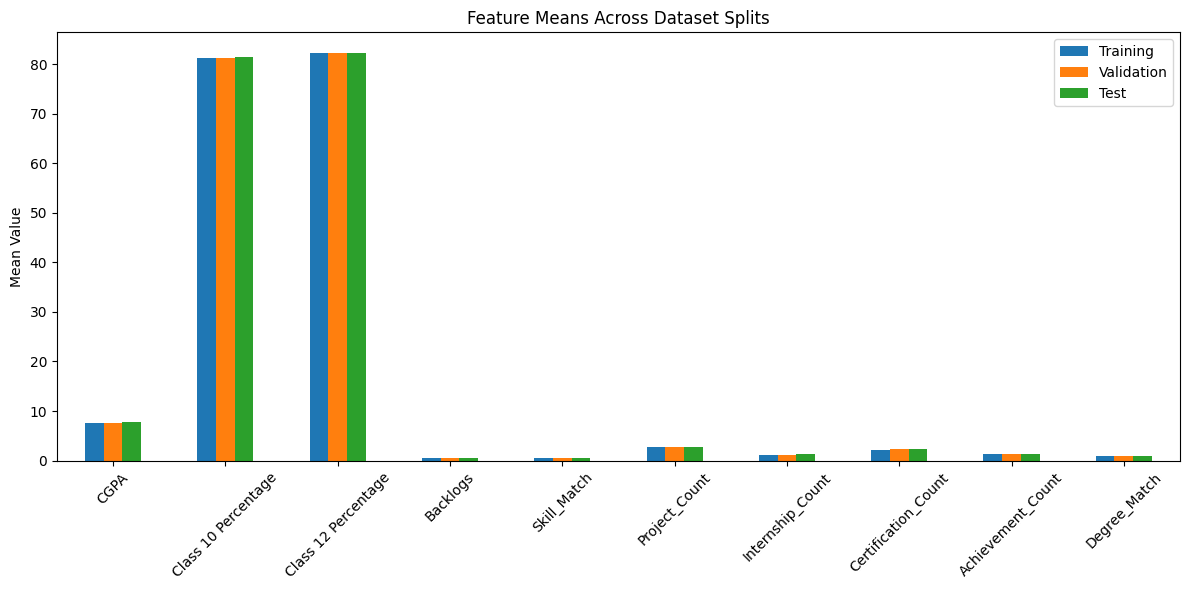

In [7]:
split_means.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Feature Means Across Dataset Splits")
plt.ylabel("Mean Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [8]:
train_shortlisted = X_train[y_train == 1]
val_shortlisted = X_val[y_val == 1]
test_shortlisted = X_test[y_test == 1]

In [9]:
shortlisted_means = pd.DataFrame({
    "Training": train_shortlisted.mean(),
    "Validation": val_shortlisted.mean(),
    "Test": test_shortlisted.mean()
})

shortlisted_means.round(3)

,Training,Validation,Test
CGPA,8.361,8.455,8.240
Class 10 Percentage,86.297,87.597,84.729
Class 12 Percentage,87.484,88.860,85.839
Backlogs,0.288,0.333,0.286
Skill_Match,0.970,0.987,0.953
Project_Count,4.075,4.048,4.119
Internship_Count,1.897,1.762,1.976
Certification_Count,2.925,3.000,3.048
Achievement_Count,2.048,1.714,1.881
Degree_Match,1.000,1.000,1.000


In [10]:
from sklearn.ensemble import RandomForestClassifier

X_dev = pd.concat([X_train, X_val])
y_dev = pd.concat([y_train, y_val])

final_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_dev, y_dev)

y_test_prob = final_model.predict_proba(X_test)[:, 1]

y_test_pred = (
    y_test_prob >= 0.15
).astype(int)

In [11]:
# Random Forest validation predictions

y_val_pred_rf = final_model.predict(X_val)

y_val_prob_rf = final_model.predict_proba(
    X_val
)[:, 1]

In [12]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    y_test_pred
)

print(cm)

[[3202   58]
 [  25   17]]


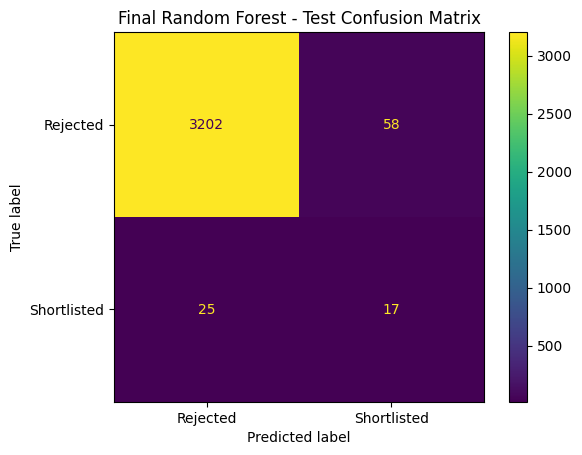

In [13]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Rejected",
        "Shortlisted"
    ]
)

disp.plot()

plt.title(
    "Final Random Forest - Test Confusion Matrix"
)

plt.show()

In [14]:
importance = pd.DataFrame({
    "Feature": features,
    "Importance": final_model.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

importance

,Feature,Importance
4,Skill_Match,0.421066
5,Project_Count,0.176455
0,CGPA,0.103867
2,Class 12 Percentage,0.078932
6,Internship_Count,0.067314
1,Class 10 Percentage,0.062436
8,Achievement_Count,0.037589
7,Certification_Count,0.036082
3,Backlogs,0.011855
9,Degree_Match,0.004404


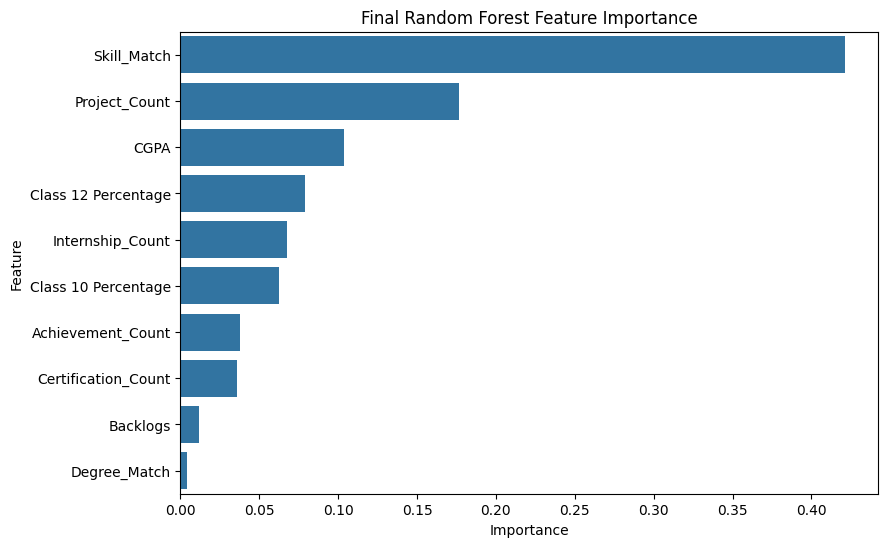

In [15]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title(
    "Final Random Forest Feature Importance"
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

In [16]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    accuracy_score
)

final_comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "PR-AUC"
    ],

    "Validation": [
        accuracy_score(y_val, y_val_pred_rf),
        precision_score(y_val, y_val_pred_rf),
        recall_score(y_val, y_val_pred_rf),
        f1_score(y_val, y_val_pred_rf),
        average_precision_score(y_val, y_val_prob_rf)
    ],

    "Test": [
        accuracy_score(y_test, y_test_pred),
        precision_score(y_test, y_test_pred),
        recall_score(y_test, y_test_pred),
        f1_score(y_test, y_test_pred),
        average_precision_score(y_test, y_test_prob)
    ]
})

final_comparison.round(4)

,Metric,Validation,Test
0,Accuracy,0.9988,0.9749
1,Precision,0.9130,0.2267
2,Recall,1.0000,0.4048
3,F1 Score,0.9545,0.2906
4,PR-AUC,0.9596,0.2798
